# Análisis exploratorio de datos e inferencia estadística – ENFR 2018

* **Materia:** Fundamentos de la Ciencia de Datos (Cursada 2026)
* **Grupo:** 40
* **Integrantes:** Blando, Lucía; Solanet, José Francisco; Serio, Tomás
* **Ayudante asignada:** Rosana Cepeda

> **Nota metodológica:** Todos los estadísticos descriptivos, modelos y contrastes de hipótesis del presente cuaderno se calculan sobre los registros muestrales sin aplicar el factor de expansión (`pondera`).

## 1. Carga y descripción del dataset

In [1]:
# Carga del conjunto de datos
import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Rutas de los archivos
ruta_zip = "../data/raw/ENFR2018_baseusuario.zip"
ruta_salida = "../data/ENFR2018"

# Descomprimimos el archivo si todavía no existe la carpeta
if not os.path.exists(ruta_salida):
    with zipfile.ZipFile(ruta_zip, "r") as zip_ref:
        zip_ref.extractall(ruta_salida)
    print("Archivo descomprimido correctamente.")
else:
    print("La carpeta ENFR2018 ya existe.")

# Leemos el archivo CSV directamente desde el ZIP
df = pd.read_csv(ruta_zip, sep="|")

# Revisamos las dimensiones y los tipos de datos
print("Cantidad de filas:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])

df.info()

# Nombres de las columnas
print(df.columns.tolist())

La carpeta ENFR2018 ya existe.
Cantidad de filas: 29224
Cantidad de columnas: 287
<class 'pandas.DataFrame'>
RangeIndex: 29224 entries, 0 to 29223
Columns: 287 entries, id to wf3p
dtypes: float64(186), int64(101)
memory usage: 64.0 MB
['id', 'cod_provincia', 'region', 'tamanio_aglomerado', 'aglomerado', 'localidades_150', 'submuestra', 'bhcv01', 'bhcv02', 'bhcv03', 'bhcv04', 'bhcv05', 'bhcv06', 'bhcv07', 'bhcv08', 'bhcv09', 'bhcv10', 'bhcv11', 'bhho01', 'bhho02', 'bhho03', 'cant_componentes', 'miembros_18', 'tipo_hogar', 'bhih01', 'bhih01_02', 'rango_ingreso', 'quintil_uc', 'imputado', 'bhih03', 'bhch03_j', 'bhch04_j', 'rango_edad_j', 'bhch05_j', 'nivel_instruccion_j', 'nivel_instruccion_agrupado_j', 'bhch10_01_j', 'bhch10_02_j', 'bhch10_03_j', 'bhch10_04_j', 'bhch10_05_j', 'bhch10_06_j', 'bhch10_99_j', 'cobertura_salud_j', 'bhsl01', 'bhsl02', 'bhsl03', 'bhsl04', 'bhsl05', 'bhsl06', 'condicion_actividad_j', 'bhch02', 'bhch03', 'bhch04', 'rango_edad', 'bhch05', 'nivel_instruccion', 'niv

## 2. Revisión inicial de valores faltantes

In [2]:
#Análisis de valores nulos
nulos = df.isnull().sum()
print(nulos[nulos > 0].sort_values(ascending=False))

porcentaje_nulos = (df.isnull().sum() / len(df) * 100)
print(porcentaje_nulos[porcentaje_nulos > 0].sort_values(ascending=False))

porcentaje_nulos = df.isnull().sum() / len(df) * 100

print("Sin nulos:", (porcentaje_nulos == 0).sum())
print("Hasta 10%:", ((porcentaje_nulos > 0) & (porcentaje_nulos <= 10)).sum())
print("Entre 10% y 50%:", ((porcentaje_nulos > 10) & (porcentaje_nulos <= 50)).sum())
print("Entre 50% y 90%:", ((porcentaje_nulos > 50) & (porcentaje_nulos <= 90)).sum())
print("Más del 90%:", (porcentaje_nulos > 90).sum())

bita06_b_99                   29207
biha06_99                     29201
biaf02_99                     29186
biha11_99                     29178
biaf04_99                     29169
                              ...  
consumo_episodico_excesivo      154
consumo_regular_riesgo          154
bhcv10                          122
bhcv11                          122
bhho01                          122
Length: 186, dtype: int64
bita06_b_99                   99.941829
biha06_99                     99.921298
biaf02_99                     99.869970
biha11_99                     99.842595
biaf04_99                     99.811799
                                ...    
consumo_episodico_excesivo     0.526964
consumo_regular_riesgo         0.526964
bhcv10                         0.417465
bhcv11                         0.417465
bhho01                         0.417465
Length: 186, dtype: float64
Sin nulos: 101
Hasta 10%: 17
Entre 10% y 50%: 47
Entre 50% y 90%: 75
Más del 90%: 47


## 3. Análisis exploratorio por dimensiones

### 3.1. Estadísticos descriptivos de las dimensiones

Edad - Media: 46.49 | Desv. estándar: 18.05 | Máximo: 104
Registros >= 100 años: 1 (0.0034%)

Ingresos > $60.000: 965 (3.30%)
Registros > $300.000:
 bhih01
350000    7
420000    2
Name: count, dtype: int64
Edad - Media: 46.49 años | Mediana: 44.0 años


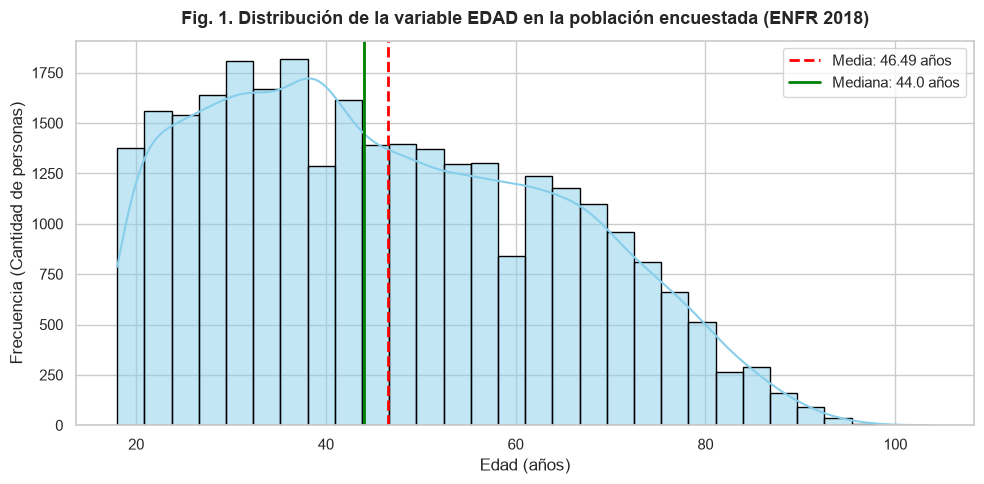


Distribución por Sexo:
        Cantidad  Porcentaje (%)
bhch03                          
2          16632           56.91
1          12592           43.09

Nivel Educativo Agrupado (%):
nivel_instruccion_agrupado
3    55.61
2    35.22
1     9.17
Name: proportion, dtype: float64

Ingreso del Hogar (bhih01) - Media: $22446.65 | Mediana: $18000.00

=== 2. DIMENSIÓN HÁBITOS ===
Condición de Fumador (%):
consumo_tabaco_100
3    58.85
1    21.38
2    19.77
Name: proportion, dtype: float64

Porcentaje que consumió alcohol en los últimos 30 días: 48.17%

Uso de sal en la mesa (%):
bial02
3    63.59
2    23.35
1    13.06
Name: proportion, dtype: float64

Consumo de Frutas/Verduras - Porciones diarias (Media): 2.07 | Mediana: 1.64
Porcentaje que consume al menos 5 porciones diarias: 6.06%

=== 3. DIMENSIÓN SALUD ===
Prevalencia de Hipertensión (Autorreporte): 35.10%
Prevalencia de Diabetes (Autorreporte): 13.43%
Prevalencia de Colesterol Alto (Autorreporte): 21.52%

IMC continuo - Media: 27.30 

In [3]:
# Estadísticos descriptivos de las dimensiones
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


# Resumen de la variable edad
promedio_edad = df['bhch04'].mean()
desviacion_edad = df['bhch04'].std()
edad_maxima = df['bhch04'].max()

# Resumen de la variable edad y auditoría de casos extremos
promedio_edad = df['bhch04'].mean()
desviacion_edad = df['bhch04'].std()
edad_maxima = df['bhch04'].max()
centenarios = (df['bhch04'] >= 100).sum()

print(f"Edad - Media: {promedio_edad:.2f} | Desv. estándar: {desviacion_edad:.2f} | Máximo: {edad_maxima}")
print(f"Registros >= 100 años: {centenarios} ({centenarios / len(df) * 100:.4f}%)")

# Auditoría de ingresos elevados (bhih01)
mayores_60k = (df['bhih01'] > 60000).sum()
mayores_300k = df[df['bhih01'] > 300000]['bhih01'].value_counts()
print(f"\nIngresos > $60.000: {mayores_60k} ({mayores_60k / len(df) * 100:.2f}%)")
print("Registros > $300.000:\n", mayores_300k)

# Edad (bhch04)
edad = df['bhch04'].dropna()

media_edad = edad.mean()
mediana_edad = edad.median()

print(f"Edad - Media: {media_edad:.2f} años | Mediana: {mediana_edad:.1f} años")

# Histograma de edad con media y mediana
plt.figure(figsize=(10, 5))

sns.histplot(
    edad,
    bins=30,
    kde=True,
    color='skyblue',
    edgecolor='black'
)

plt.axvline(
    media_edad,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Media: {media_edad:.2f} años',
)

plt.axvline(
    mediana_edad,
    color='green',
    linestyle='-',
    linewidth=2,
    label=f'Mediana: {mediana_edad:.1f} años',
)

plt.title(
    'Fig. 1. Distribución de la variable EDAD en la población encuestada (ENFR 2018)',
    fontsize=13,
    fontweight='bold',
    pad=12,
)

plt.xlabel('Edad (años)', fontsize=12)
plt.ylabel('Frecuencia (Cantidad de personas)', fontsize=12)
plt.legend(fontsize=11, loc='upper right')

plt.tight_layout()
plt.savefig('fig1_distribucion_edad.png', dpi=300)
plt.show()


# Sexo (bhch03: 1=Varón, 2=Mujer)
sexo_counts = df['bhch03'].value_counts()
sexo_pct = df['bhch03'].value_counts(normalize=True) * 100

print("\nDistribución por Sexo:")
print(pd.DataFrame({
    'Cantidad': sexo_counts,
    'Porcentaje (%)': sexo_pct.round(2)
}))


# Nivel Educativo Agrupado
edu_pct = df['nivel_instruccion_agrupado'].value_counts(normalize=True) * 100

print("\nNivel Educativo Agrupado (%):")
print(edu_pct.round(2))


# Ingresos del Hogar (bhih01)
print(
    f"\nIngreso del Hogar (bhih01) - Media: ${df['bhih01'].mean():.2f} "
    f"| Mediana: ${df['bhih01'].median():.2f}"
)


# Dimensión 2: Estilo de vida y hábitos
# ---------------------------------------------------------

print("\n=== 2. DIMENSIÓN HÁBITOS ===")

# Tabaco
fuma_pct = df['consumo_tabaco_100'].value_counts(normalize=True) * 100

print("Condición de Fumador (%):")
print(fuma_pct.round(2))


# Consumo de Alcohol en últimos 30 días
alcohol_30d = (df['bica02'] == 1).mean() * 100

print(f"\nPorcentaje que consumió alcohol en los últimos 30 días: {alcohol_30d:.2f}%")


# Agregado de Sal en la mesa
sal_pct = df['bial02'].value_counts(normalize=True) * 100

print("\nUso de sal en la mesa (%):")
print(sal_pct.round(2))


# Consumo diario de Frutas y Verduras
media_fv = df['promedio_fv_diario'].mean()
mediana_fv = df['promedio_fv_diario'].median()
cumple_5_porciones = (df['consumo_fv'] == 1).mean() * 100

print(
    f"\nConsumo de Frutas/Verduras - Porciones diarias "
    f"(Media): {media_fv:.2f} | Mediana: {mediana_fv:.2f}"
)

print(f"Porcentaje que consume al menos 5 porciones diarias: {cumple_5_porciones:.2f}%")


# Dimensión 3: Salud y enfermedades no transmisibles
# ---------------------------------------------------------

print("\n=== 3. DIMENSIÓN SALUD ===")

# Prevalencia de Hipertensión
hip_pct = (df['prevalencia_hipertension'] == 1).mean() * 100

print(f"Prevalencia de Hipertensión (Autorreporte): {hip_pct:.2f}%")


# Prevalencia de Diabetes
diab_pct = (df['prevalencia_diabetes'] == 1).mean() * 100

print(f"Prevalencia de Diabetes (Autorreporte): {diab_pct:.2f}%")


# Prevalencia de Colesterol Alto
col_pct = (df['prevalencia_colesterol'] == 1).mean() * 100

print(f"Prevalencia de Colesterol Alto (Autorreporte): {col_pct:.2f}%")


# Índice de Masa Corporal (IMC)
imc_media = df['imc'].mean()
imc_mediana = df['imc'].median()
imc_cat_pct = df['imc_categorias'].value_counts(normalize=True) * 100

print(
    f"\nIMC continuo - Media: {imc_media:.2f} kg/m² "
    f"| Mediana: {imc_mediana:.2f} kg/m²"
)

print("Categorías de IMC (%):")
print(imc_cat_pct.round(2))


# Revisión de la calidad de los datos
# ---------------------------------------------------------

print("\n=== 4. CALIDAD DE DATOS (NULOS Y OUTLIERS) ===")

# Variables seleccionadas para la revisión de nulos
vars_analisis = [
    'bhch04', 'bhch03', 'nivel_instruccion_agrupado', 'bhih01',
    'consumo_tabaco_100', 'bica02', 'bial02', 'promedio_fv_diario',
    'prevalencia_hipertension', 'prevalencia_diabetes',
    'prevalencia_colesterol', 'imc'
]

# Conteos de valores nulos
nulos_df = pd.DataFrame({
    'Valores Nulos': df[vars_analisis].isnull().sum(),
    'Porcentaje (%)': (df[vars_analisis].isnull().mean() * 100).round(2)
})

print("Reporte de Valores Nulos por Variable:")
print(nulos_df)


# Rangos Mínimos y Máximos
print("\nRangos observados (Mínimo - Máximo):")

for col_cont in ['bhch04', 'bhih01', 'promedio_fv_diario', 'imc']:
    if col_cont in df.columns:
        print(f"{col_cont}: Min = {df[col_cont].min()} | Max = {df[col_cont].max()}")

### 3.2. Dimensión 1: análisis gráfico de ingresos del hogar

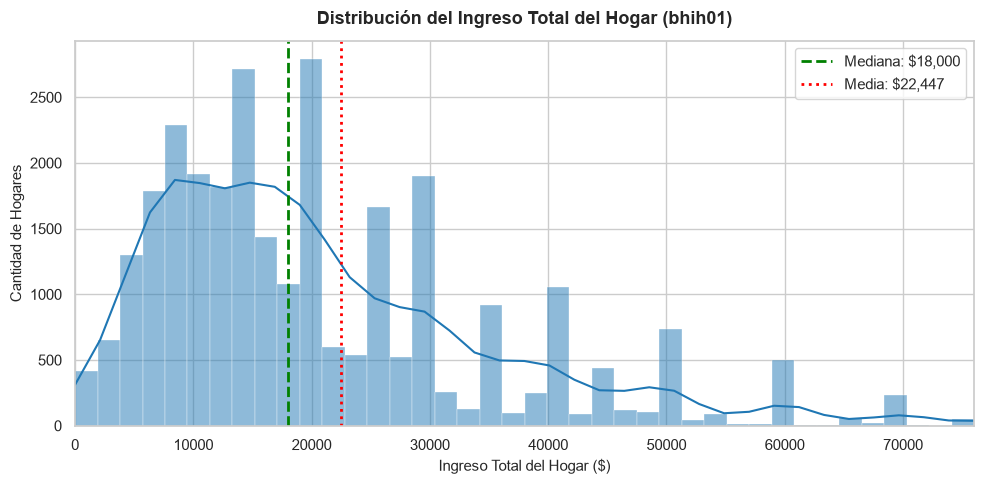

C:\Users\Fran\AppData\Local\Temp\ipykernel_8504\1334812679.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['rango_ingreso_completo'] = pd.cut(


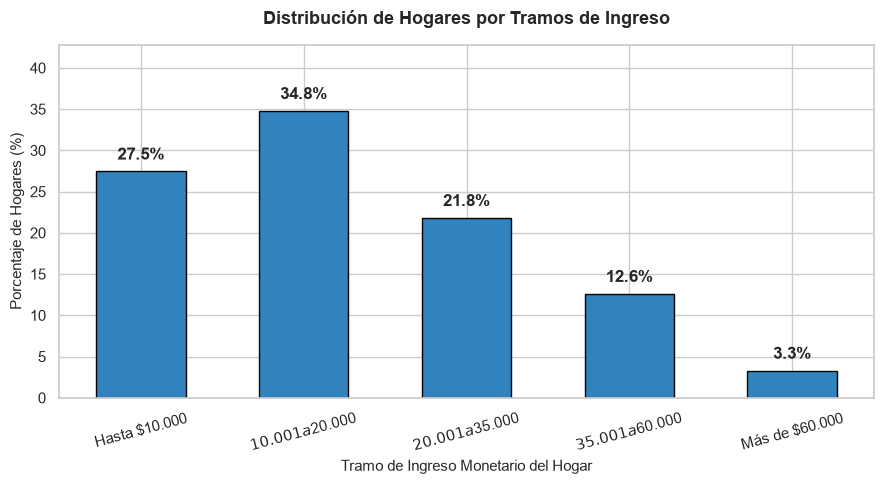

In [4]:
# Distribución de los ingresos del hogar (bhih01)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")


# Histograma de ingresos
plt.figure(figsize=(10, 5))

# Limitamos el eje para que los valores extremos no compriman el gráfico
limite_x = df['bhih01'].quantile(0.98)

# Histograma con curva de densidad
sns.histplot(
    df['bhih01'],
    bins=40,
    binrange=(0, limite_x),
    color='#1f77b4',
    kde=True,
)

# Media y mediana
media_val = df['bhih01'].mean()
mediana_val = df['bhih01'].median()

# Agregamos las líneas de referencia
plt.axvline(
    mediana_val,
    color='green',
    linestyle='--',
    linewidth=2,
    label=f'Mediana: ${mediana_val:,.0f}',
)

plt.axvline(
    media_val,
    color='red',
    linestyle=':',
    linewidth=2,
    label=f'Media: ${media_val:,.0f}',
)

plt.title(
    'Distribución del Ingreso Total del Hogar (bhih01)',
    fontsize=13,
    fontweight='bold',
    pad=12,
)

plt.xlim(0, limite_x)
plt.xlabel('Ingreso Total del Hogar ($)', fontsize=11)
plt.ylabel('Cantidad de Hogares', fontsize=11)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig('bhih01_histograma_final.png', dpi=300)
plt.show()



# Distribución por tramos de ingreso

plt.figure(figsize=(9, 5))

bins_fijos = [-np.inf, 10000, 20000, 35000, 60000, np.inf]

labels_fijos = [
    'Hasta $10.000',
    '$10.001 a $20.000',
    '$20.001 a $35.000',
    '$35.001 a $60.000',
    'Más de $60.000',
]

df['rango_ingreso_completo'] = pd.cut(
    df['bhih01'], bins=bins_fijos, labels=labels_fijos
)

pct_tramos = (
    df['rango_ingreso_completo'].value_counts(normalize=True).sort_index() * 100
)

bars = plt.bar(
    pct_tramos.index,
    pct_tramos.values,
    color='#3182bd',
    edgecolor='black',
    width=0.55,
)

plt.title(
    'Distribución de Hogares por Tramos de Ingreso',
    fontsize=13,
    fontweight='bold',
    pad=15,
)

plt.ylabel('Porcentaje de Hogares (%)', fontsize=11)
plt.xlabel('Tramo de Ingreso Monetario del Hogar', fontsize=11)
plt.ylim(0, max(pct_tramos.values) + 8)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 1,
        f'{yval:.1f}%',
        ha='center',
        va='bottom',
        fontweight='bold',
    )

plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('rango_ingreso_barras_final.png', dpi=300)
plt.show()

### 3.3. Dimensión 1: comparación de métodos de imputación

In [5]:
# ANALISIS DE IMPUTACIÓN DE DATOS PARA LA VARIABLE bhih01
import numpy as np
import pandas as pd
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

# 1. Enmascarar los registros imputados oficialmente por INDEC (43,06 %) para simular los nulos originales
mascara_imputados = pd.to_numeric(df['imputado'], errors='coerce').eq(1)
df['bhih01_clean'] = pd.to_numeric(df['bhih01'], errors='coerce').copy()
df.loc[mascara_imputados, 'bhih01_clean'] = np.nan

# 2. Generación de imputaciones por mediana y media
mediana_val = df['bhih01_clean'].median()
media_val = df['bhih01_clean'].mean()

df['bhih01_mediana'] = df['bhih01_clean'].fillna(mediana_val)
df['bhih01_media'] = df['bhih01_clean'].fillna(media_val)

# 3. Imputación por KNN (k=5) con variables auxiliares estandarizadas (StandardScaler)
datos_knn = pd.DataFrame({
    'edad': pd.to_numeric(df['bhch04'], errors='coerce'),
    'sexo': df['bhch03'].map({1: 0, 2: 1}),
    'ingreso': df['bhih01_clean'],
})

escalador = StandardScaler()
datos_escalados = escalador.fit_transform(datos_knn)

imputer_knn = KNNImputer(n_neighbors=5)
datos_imputados = imputer_knn.fit_transform(datos_escalados)

# Recuperar la escala original del ingreso
df['bhih01_knn'] = (
    datos_imputados[:, 2] * escalador.scale_[2] + escalador.mean_[2]
)
df['bhih01_knn'] = df['bhih01_knn'].fillna(mediana_val)

# 4. Consolidación de estadísticos descriptivos en un solo DataFrame
tabla_comparativa = pd.DataFrame({
    'Original (sin nulos)': df['bhih01_clean'].describe(),
    'Imp. Mediana': df['bhih01_mediana'].describe(),
    'Imp. Media': df['bhih01_media'].describe(),
    'Imp. KNN (k=5)': df['bhih01_knn'].describe(),
})

pd.set_option('display.float_format', lambda x: '%.2f' % x)

print('=== TABLA COMPARATIVA DE ESTADÍSTICOS DESCRIPTIVOS (bhih01) ===')
print(tabla_comparativa)

C:\Users\Fran\AppData\Local\Temp\ipykernel_8504\2117000411.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['bhih01_clean'] = pd.to_numeric(df['bhih01'], errors='coerce').copy()
C:\Users\Fran\AppData\Local\Temp\ipykernel_8504\2117000411.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['bhih01_mediana'] = df['bhih01_clean'].fillna(mediana_val)
C:\Users\Fran\AppData\Local\Temp\ipykernel_8504\2117000411.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many

=== TABLA COMPARATIVA DE ESTADÍSTICOS DESCRIPTIVOS (bhih01) ===
       Original (sin nulos)  Imp. Mediana  Imp. Media  Imp. KNN (k=5)
count              16640.00      29224.00    29224.00        29224.00
mean               21818.92      19743.87    21818.92        23663.34
std                19487.83      14897.34    14704.99        17601.32
min                    0.00          0.00        0.00            0.00
25%                10000.00      15000.00    15000.00        13000.00
50%                17000.00      17000.00    21818.92        20000.00
75%                30000.00      20000.00    21818.92        30000.00
max               420000.00     420000.00   420000.00       420000.00


C:\Users\Fran\AppData\Local\Temp\ipykernel_8504\2117000411.py:33: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['bhih01_knn'] = (


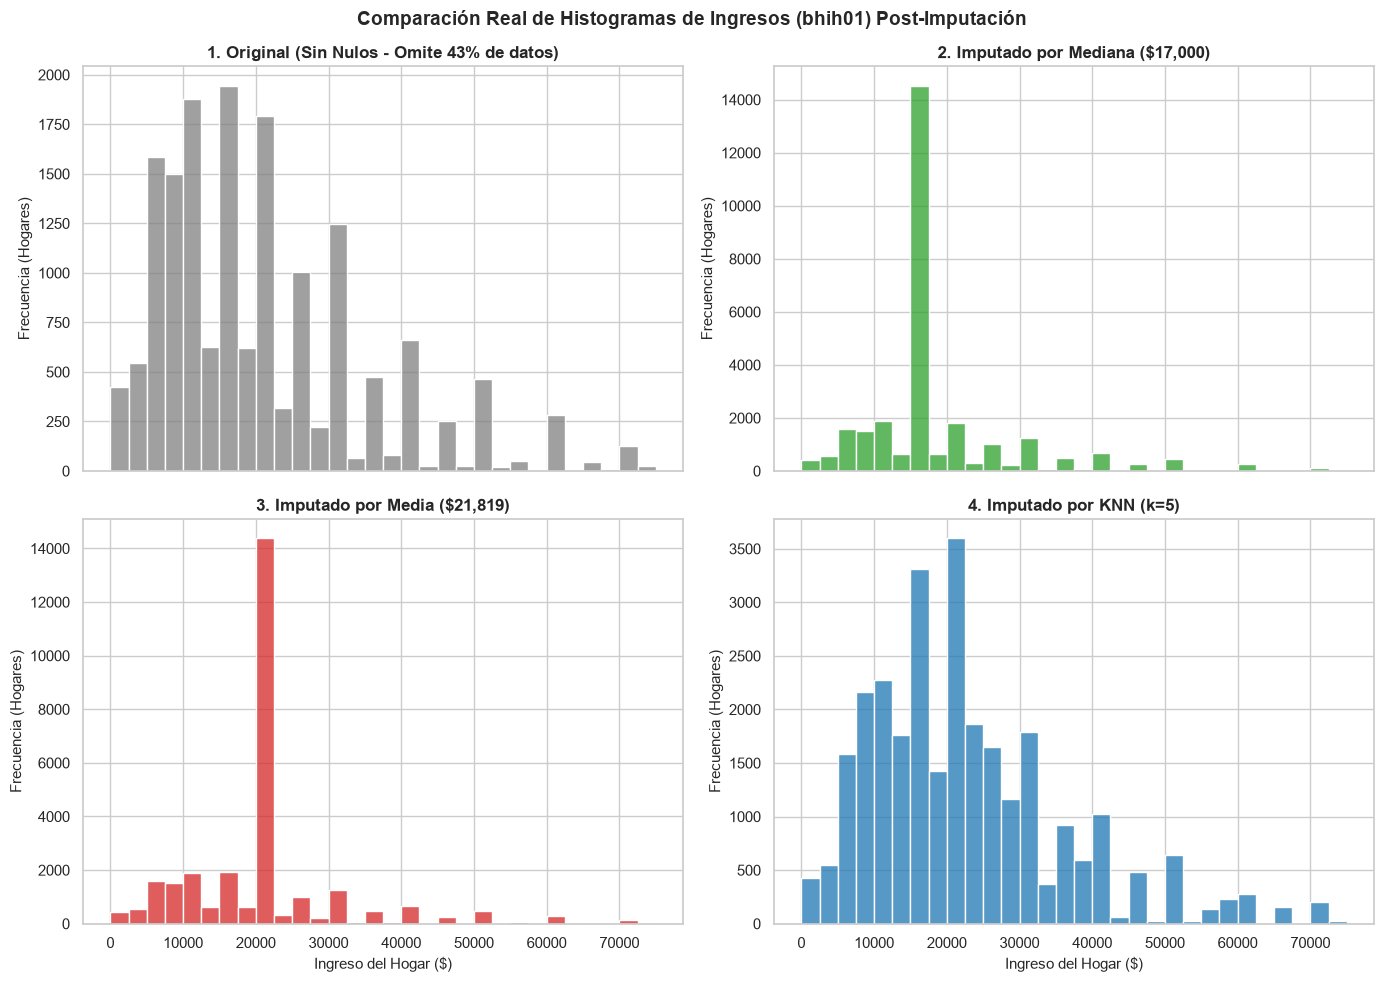

In [6]:
# ANALISIS DE IMPUTACIÓN DE DATOS PARA LA VARIABLE bhih01 (Fig. 3)
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# 1. Definir límite superior razonable (percentil 98) para ignorar outliers extremos en la visualización
limite_x = df['bhih01_clean'].quantile(0.98)

# 2. Generar histogramas usando las variables ya imputadas en la celda anterior (KNN estandarizado)
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)

# Original
sns.histplot(
    df['bhih01_clean'].dropna(),
    ax=axes[0, 0],
    bins=30,
    binrange=(0, limite_x),
    color='gray',
)
axes[0, 0].set_title(
    '1. Original (Sin Nulos - Omite 43% de datos)', fontweight='bold'
)

# Mediana
sns.histplot(
    df['bhih01_mediana'],
    ax=axes[0, 1],
    bins=30,
    binrange=(0, limite_x),
    color='#2ca02c',
)
axes[0, 1].set_title(
    f'2. Imputado por Mediana (${mediana_val:,.0f})', fontweight='bold'
)

# Media
sns.histplot(
    df['bhih01_media'],
    ax=axes[1, 0],
    bins=30,
    binrange=(0, limite_x),
    color='#d62728',
)
axes[1, 0].set_title(
    f'3. Imputado por Media (${media_val:,.0f})', fontweight='bold'
)

# KNN (estandarizado con StandardScaler)
sns.histplot(
    df['bhih01_knn'],
    ax=axes[1, 1],
    bins=30,
    binrange=(0, limite_x),
    color='#1f77b4',
)
axes[1, 1].set_title('4. Imputado por KNN (k=5)', fontweight='bold')

for ax in axes.flat:
  ax.set_xlabel('Ingreso del Hogar ($)', fontsize=11)
  ax.set_ylabel('Frecuencia (Hogares)', fontsize=11)

plt.suptitle(
    'Comparación Real de Histogramas de Ingresos (bhih01) Post-Imputación',
    fontsize=14,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

### 3.4. Dimensión 2: estilos de vida y habitos

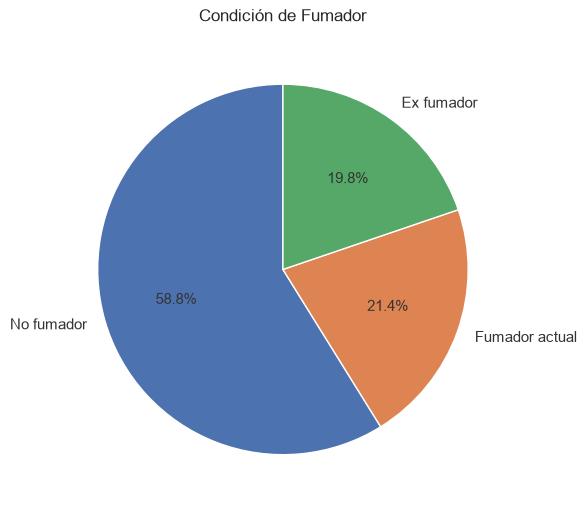

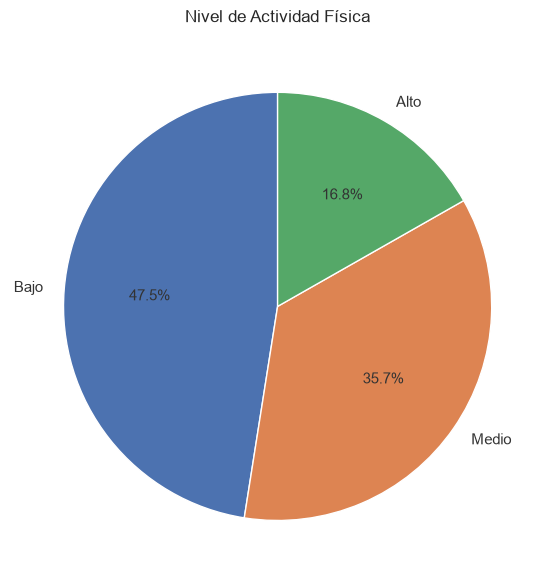

In [7]:
# Dimensión 2: Condición de fumador (Fig. 4) y Nivel de actividad física (Fig. 5)
sns.set_theme(style="white")
colores_dim2 = ['#4C72B0', '#DD8452', '#55A868']

# 1. Condición de fumador (1=Fumador actual, 2=Ex fumador, 3=No fumador)
mapa_tabaco = {1: 'Fumador actual', 2: 'Ex fumador', 3: 'No fumador'}
conteos_tabaco = df['consumo_tabaco_100'].map(mapa_tabaco).dropna().value_counts()

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    conteos_tabaco.values,
    labels=conteos_tabaco.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colores_dim2,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1},
    textprops={'fontsize': 10.5, 'color': '#333333'}
)
ax.set_title('Condición de Fumador', fontsize=12, pad=12)
plt.tight_layout()
plt.show()

# 2. Nivel de actividad física (1=Alto, 2=Medio, 3=Bajo)
mapa_af = {1: 'Alto', 2: 'Medio', 3: 'Bajo'}
conteos_af = df['nivel_actividad_fisica'].map(mapa_af).dropna().value_counts()

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    conteos_af.values,
    labels=conteos_af.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colores_dim2,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1},
    textprops={'fontsize': 10.5, 'color': '#333333'}
)
ax.set_title('Nivel de Actividad Física', fontsize=12, pad=12)
plt.tight_layout()
plt.show()

### 3.5. Dimensión 3: salud y enfermedades no transmisibles

ESTADO NUTRICIONAL (SOBRE CASOS VÁLIDOS):
imc_categorias
Sobrepeso          37.26
Normopeso / Bajo   36.78
Obesidad           25.96
Name: proportion, dtype: float64
Registros sin categoría válida: 0 (0.00%)


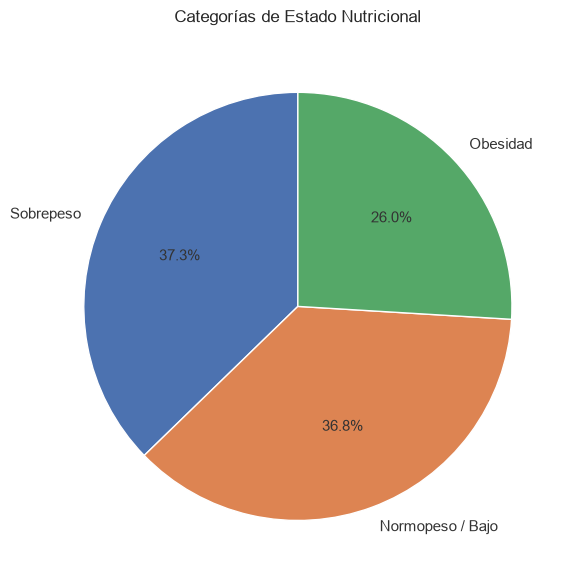


PREVALENCIAS DE ECNT SOBRE RESPUESTAS VÁLIDAS:
Hipertensión: 38.01% | Colesterol: 30.77% | Diabetes: 13.49%


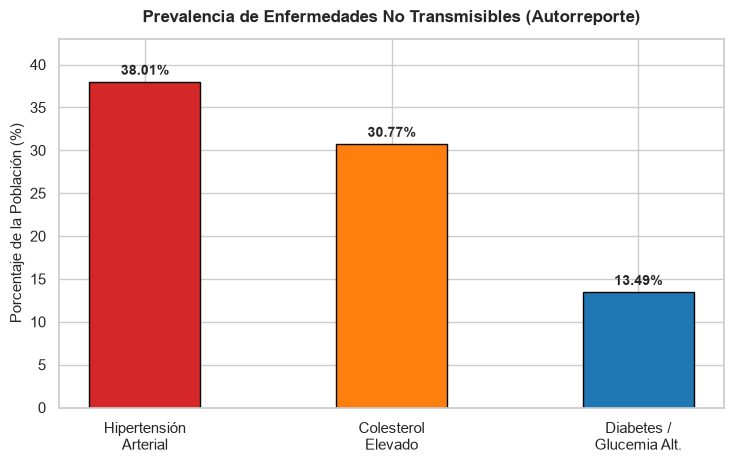

In [8]:
# Dimensión 3: Salud y enfermedades no transmisibles (Figs. 6 y 7)
sns.set_theme(style="white")

def prevalencia_sobre_validos(serie):
    respuestas_validas = serie[serie.isin([1, 2])]
    return (respuestas_validas == 1).mean() * 100

# 1. Estado nutricional sobre casos válidos (Fig. 6)
mapa_imc = {1: 'Normopeso / Bajo', 2: 'Sobrepeso', 3: 'Obesidad'}
serie_imc_valida = df['imc_categorias'].map(mapa_imc).dropna()
conteos_imc = serie_imc_valida.value_counts()

print("ESTADO NUTRICIONAL (SOBRE CASOS VÁLIDOS):")
print((serie_imc_valida.value_counts(normalize=True) * 100).round(2))
print(f"Registros sin categoría válida: {df['imc_categorias'].isna().sum()} ({df['imc_categorias'].isna().mean()*100:.2f}%)")

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    conteos_imc.values,
    labels=conteos_imc.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#4C72B0', '#DD8452', '#55A868'],
    wedgeprops={'edgecolor': 'white', 'linewidth': 1},
    textprops={'fontsize': 10.5, 'color': '#333333'}
)
ax.set_title('Categorías de Estado Nutricional', fontsize=12, pad=12)
plt.tight_layout()
plt.show()

# 2. Prevalencia de ECNT autorreportadas (Fig. 7)
a_hipertension = prevalencia_sobre_validos(df['prevalencia_hipertension'])
b_diabetes = prevalencia_sobre_validos(df['prevalencia_diabetes'])
c_colesterol = prevalencia_sobre_validos(df['prevalencia_colesterol'])

print("\nPREVALENCIAS DE ECNT SOBRE RESPUESTAS VÁLIDAS:")
print(f"Hipertensión: {a_hipertension:.2f}% | Colesterol: {c_colesterol:.2f}% | Diabetes: {b_diabetes:.2f}%")

sns.set_theme(style="whitegrid")
etiquetas_ecnt = ['Hipertensión\nArterial', 'Colesterol\nElevado', 'Diabetes /\nGlucemia Alt.']
valores_ecnt = [a_hipertension, c_colesterol, b_diabetes]
colores_ecnt = ['#d62728', '#ff7f0e', '#1f77b4']

fig, ax = plt.subplots(figsize=(7.5, 4.8))
barras = ax.bar(etiquetas_ecnt, valores_ecnt, color=colores_ecnt, edgecolor='black', width=0.45)
ax.set_ylabel('Porcentaje de la Población (%)', fontsize=11)
ax.set_title('Prevalencia de Enfermedades No Transmisibles (Autorreporte)', fontsize=12, fontweight='bold', pad=12)
ax.set_ylim(0, 43)

for barra, val in zip(barras, valores_ecnt):
    ax.text(barra.get_x() + barra.get_width() / 2, val + 0.8, f'{val:.2f}%', ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

## 4. Planteo y análisis de hipótesis

### 4.1. Hipótesis 1: ingresos del hogar (univariada)

Casos válidos (N): 29224
Media: $22,446.65 | Mediana: $18,000.00
Diferencia observada (Media - Mediana): $4,446.65
Límite inferior unilateral IC 95% (Bootstrap): $4,255.81

Análisis de sensibilidad (excluyendo > $300.000, N=29215):
Media: $22,340.96 | Mediana: $18,000.00


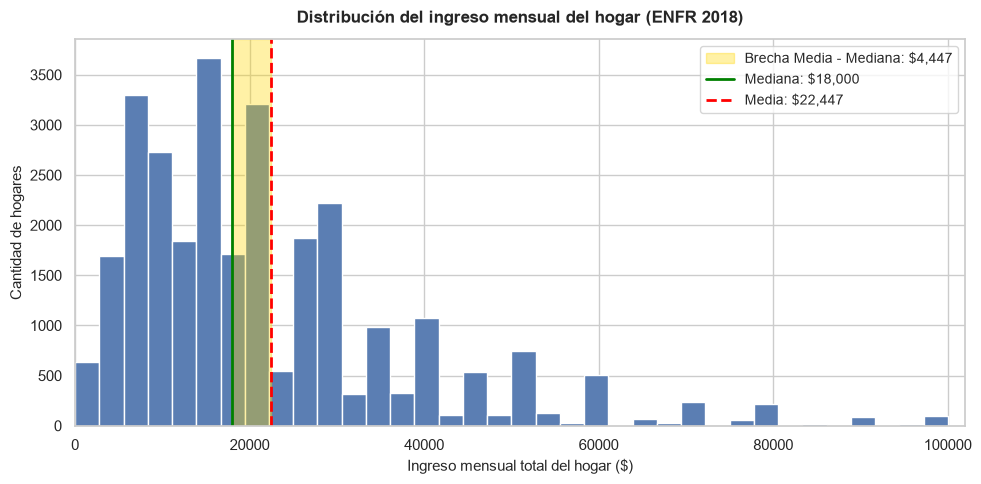

In [9]:
# Hipótesis 1 (univariada): Bootstrap para diferencia Media - Mediana en bhih01
np.random.seed(42)
ingresos = df['bhih01'].dropna().values

media_ing = np.mean(ingresos)
mediana_ing = np.median(ingresos)
diff_obs = media_ing - mediana_ing

# Remuestreo Bootstrap (10.000 réplicas)
n_boot = 10000
diffs_boot = np.empty(n_boot)
n_ing = len(ingresos)

for i in range(n_boot):
    muestra = np.random.choice(ingresos, size=n_ing, replace=True)
    diffs_boot[i] = np.mean(muestra) - np.median(muestra)

ic_inf_95 = np.percentile(diffs_boot, 5)

print(f"Casos válidos (N): {n_ing}")
print(f"Media: ${media_ing:,.2f} | Mediana: ${mediana_ing:,.2f}")
print(f"Diferencia observada (Media - Mediana): ${diff_obs:,.2f}")
print(f"Límite inferior unilateral IC 95% (Bootstrap): ${ic_inf_95:,.2f}")

# Análisis de sensibilidad excluyendo registros > $300.000
ingresos_sens = ingresos[ingresos <= 300000]
print(f"\nAnálisis de sensibilidad (excluyendo > $300.000, N={len(ingresos_sens)}):")
print(f"Media: ${np.mean(ingresos_sens):,.2f} | Mediana: ${np.median(ingresos_sens):,.2f}")

# Gráfico Fig. 8: Histograma acotado hasta $100.000 con brecha Media - Mediana
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(ingresos[ingresos <= 100000], bins=36, color='#5b7eb3', edgecolor='white')
ax.axvspan(mediana_ing, media_ing, color='gold', alpha=0.35, label=f'Brecha Media - Mediana: ${diff_obs:,.0f}')
ax.axvline(mediana_ing, color='green', linestyle='-', linewidth=2, label=f'Mediana: ${mediana_ing:,.0f}')
ax.axvline(media_ing, color='red', linestyle='--', linewidth=2, label=f'Media: ${media_ing:,.0f}')

ax.set_title('Distribución del ingreso mensual del hogar (ENFR 2018)', fontsize=12.5, fontweight='bold', pad=12)
ax.set_xlabel('Ingreso mensual total del hogar ($)', fontsize=11)
ax.set_ylabel('Cantidad de hogares', fontsize=11)
ax.set_xlim(0, 102000)
ax.legend(fontsize=10, loc='upper right')
plt.tight_layout()
plt.show()

### 4.2. Hipótesis 2: actividad física y consumo de tabaco (bivariada)

In [10]:
# Estadisticos Chi-cuadrado para la relación entre consumo de tabaco y nivel de actividad física
import pandas as pd
from scipy.stats import chi2_contingency

# Tabla de contingencia
tabla = pd.crosstab(
    df['consumo_tabaco_100'],
    df['nivel_actividad_fisica']
)

print(tabla)

# Test Chi-cuadrado
chi2, p_value, gl, esperados = chi2_contingency(tabla)

print("Chi-cuadrado:", chi2)
print("Grados de libertad:", gl)
print("P-valor:", p_value)

# Comprobar frecuencias esperadas
print("Frecuencia esperada mínima:", esperados.min())

# porcentajes por fila de tabla 1
print("\nPorcentajes por fila (%):\n", (pd.crosstab(df['consumo_tabaco_100'], df['nivel_actividad_fisica'], normalize='index') * 100).round(1))

nivel_actividad_fisica  1.00  2.00  3.00
consumo_tabaco_100                      
1                       1092  2168  2936
2                        953  2093  2688
3                       2814  6086  8140
Chi-cuadrado: 6.086485218313072
Grados de libertad: 4
P-valor: 0.19278193234766036
Frecuencia esperada mínima: 961.7364860200207

Porcentajes por fila (%):
 nivel_actividad_fisica  1.00  2.00  3.00
consumo_tabaco_100                      
1                      17.60 35.00 47.40
2                      16.60 36.50 46.90
3                      16.50 35.70 47.80


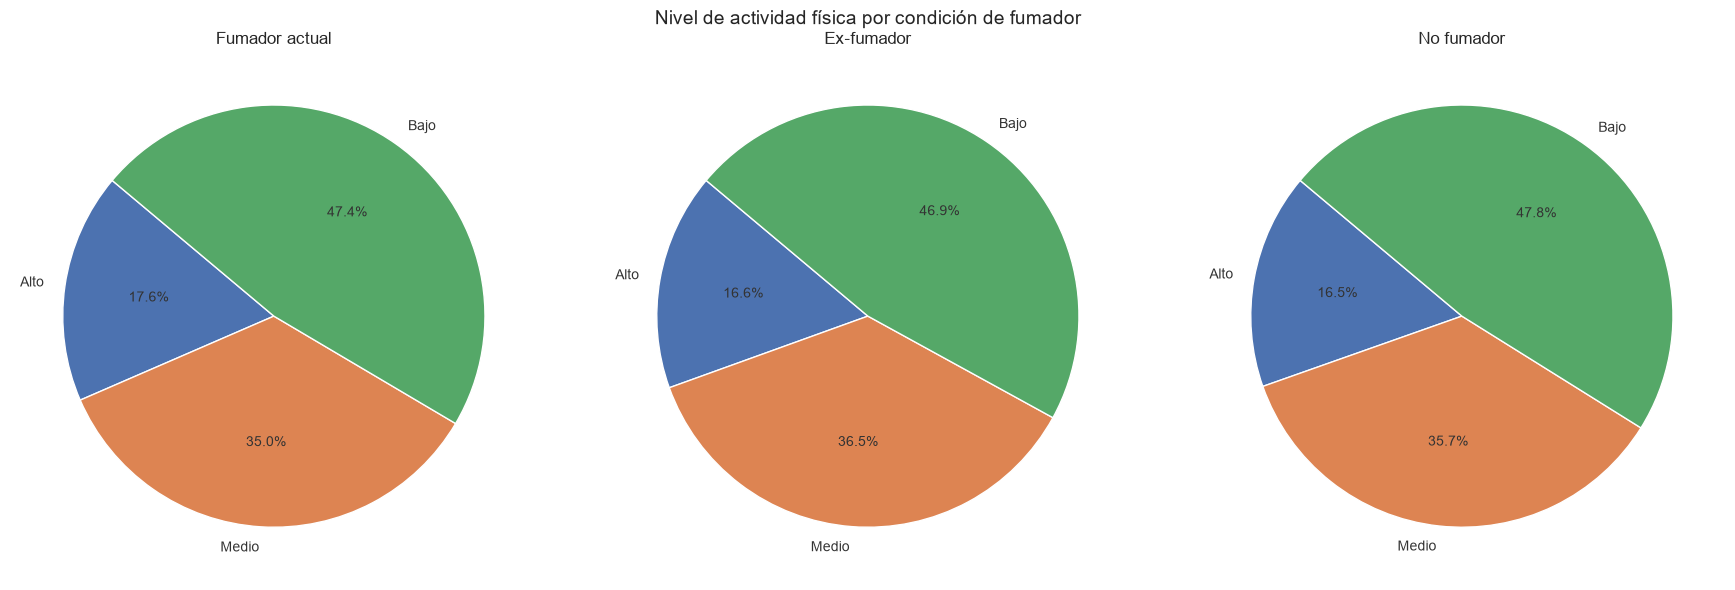

In [11]:
# Gráficos de torta para la relación entre consumo de tabaco y nivel de actividad física
sns.set_theme(style="white")

actividad_labels = {1: 'Alto', 2: 'Medio', 3: 'Bajo'}
fumador_labels = {1: 'Fumador actual', 2: 'Ex-fumador', 3: 'No fumador'}

datos_actividad = df[
    df['nivel_actividad_fisica'].isin(actividad_labels.keys()) &
    df['consumo_tabaco_100'].isin(fumador_labels.keys())
].copy()

tabla_frecuencias = pd.crosstab(
    datos_actividad['consumo_tabaco_100'],
    datos_actividad['nivel_actividad_fisica']
).reindex(
    index=fumador_labels.keys(),
    columns=actividad_labels.keys(),
    fill_value=0
)

categorias_fumador = tabla_frecuencias.index.tolist()
fig, axes = plt.subplots(
    1,
    len(categorias_fumador),
    figsize=(6 * len(categorias_fumador), 6),
)
axes = np.atleast_1d(axes)
colores_actividad = ['#4C72B0', '#DD8452', '#55A868']

for ax, categoria_fumador in zip(axes, categorias_fumador):
    ax.pie(
        tabla_frecuencias.loc[categoria_fumador],
        labels=list(actividad_labels.values()),
        autopct='%1.1f%%',
        startangle=140,
        colors=colores_actividad,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1},
        textprops={'fontsize': 10, 'color': '#333333'},
    )
    etiqueta_fumador = fumador_labels.get(
        categoria_fumador,
        f'Código {categoria_fumador}',
    )
    ax.set_title(etiqueta_fumador)

fig.suptitle('Nivel de actividad física por condición de fumador', fontsize=14)
plt.tight_layout()
plt.show()

### 4.3. Hipótesis 3: hábitos y estado de salud (multivariada)

Cantidad de registros: 29224

Estadísticas descriptivas:
                                               count  mean   std
nivel_instruccion_agrupado consumo_tabaco_100                   
1                          1                     463 52.00 17.04
                           2                     596 64.43 14.44
                           3                    1621 62.20 17.87
2                          1                    2508 42.94 15.75
                           2                    2094 54.09 17.36
                           3                    5690 49.80 19.67
3                          1                    3276 40.70 13.72
                           2                    3089 49.18 16.57
                           3                    9887 41.04 16.16

--- REGRESIÓN LINEAL MÚLTIPLE ---
                            OLS Regression Results                            
Dep. Variable:                 bhch04   R-squared:                       0.124
Model:                            O

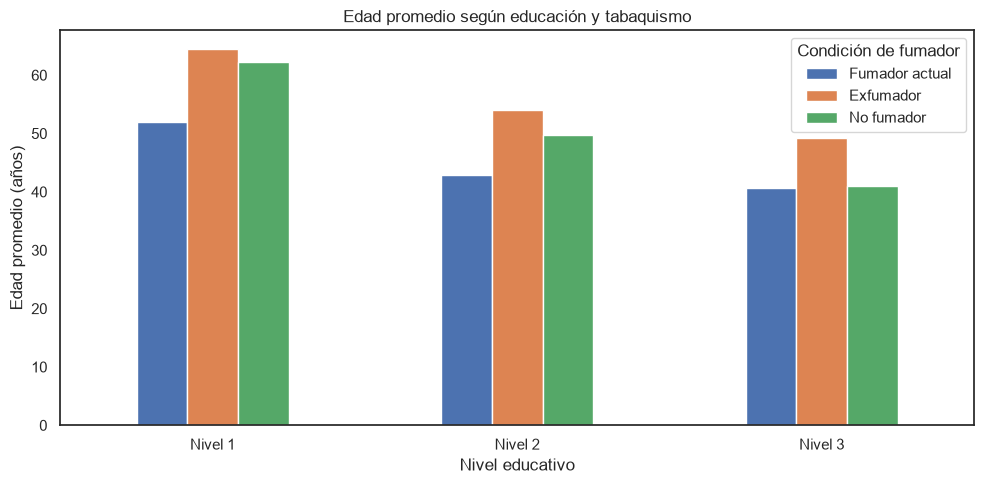

In [12]:
# HIPÓTESIS 3: Edad según nivel educativo y condición de fumador

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# 1. Selección de variables
columnas = [
    "bhch04",
    "nivel_instruccion_agrupado",
    "consumo_tabaco_100"
]

datos = df[columnas].copy().dropna()

# 2. Filtrar respuestas válidas
datos = datos[
    datos["bhch04"].between(18, 104) &
    datos["nivel_instruccion_agrupado"].isin([1, 2, 3]) &
    datos["consumo_tabaco_100"].isin([1, 2, 3])
].copy()

# 3. Estadísticas descriptivas
print("Cantidad de registros:", len(datos))

resumen = datos.groupby(
    ["nivel_instruccion_agrupado", "consumo_tabaco_100"]
)["bhch04"].agg(["count", "mean", "std"])

print("\nEstadísticas descriptivas:")
print(resumen.round(2))

# 4. Regresión lineal múltiple
# C() indica que las variables son categóricas

modelo = smf.ols(
    "bhch04 ~ C(nivel_instruccion_agrupado) + C(consumo_tabaco_100)",
    data=datos
).fit(cov_type="HC3")

# 5. Resultados del modelo
print("\n--- REGRESIÓN LINEAL MÚLTIPLE ---")
print(modelo.summary())

# 6. Contraste de hipótesis global
print("\n--- TEST GLOBAL ---")
print(f"Estadístico F: {float(modelo.fvalue):.4f}")
print(f"Valor p: {float(modelo.f_pvalue):.6g}")
print(f"R²: {modelo.rsquared:.4f}")

if modelo.f_pvalue < 0.05:
    print("Se rechaza H0.")
    print("Existe asociación estadística conjunta.")
else:
    print("No se rechaza H0.")

# Tabla de coeficientes de regresión

tabla_coeficientes = pd.DataFrame({
    "Coeficiente (β)": modelo.params,
    "Error estándar": modelo.bse,
    "Estadístico t": modelo.tvalues,
    "Valor p": modelo.pvalues,
    "IC 95% inferior": modelo.conf_int()[0],
    "IC 95% superior": modelo.conf_int()[1]
})

# Renombrar las variables para facilitar su interpretación
tabla_coeficientes.index = [
    "Intercepto",
    "Educación: nivel 2 vs. nivel 1",
    "Educación: nivel 3 vs. nivel 1",
    "Exfumador vs. fumador actual",
    "No fumador vs. fumador actual"
]

tabla_coeficientes

# 7. Gráfico de medias observadas
medias = datos.groupby(
    ["nivel_instruccion_agrupado", "consumo_tabaco_100"]
)["bhch04"].mean().unstack()

medias.columns = [
    "Fumador actual",
    "Exfumador",
    "No fumador"
]

medias.index = [
    "Nivel 1",
    "Nivel 2",
    "Nivel 3"
]



medias.plot(kind="bar", figsize=(10, 5))

plt.title("Edad promedio según educación y tabaquismo")
plt.xlabel("Nivel educativo")
plt.ylabel("Edad promedio (años)")
plt.xticks(rotation=0)
plt.legend(title="Condición de fumador")
plt.tight_layout()
plt.show()


### 4.4. Hipótesis 4: consumo de frutas y verduras (univariada)

In [13]:
# Hipotesis 4: El consumo medio diario de frutas y verduras es inferior a 5 porciones.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import ttest_1samp

# Seleccionar respuestas válidas
porciones = pd.to_numeric(
    df["promedio_fv_diario"], errors="coerce"
).dropna()

# Estadísticas descriptivas
n = len(porciones)
media = porciones.mean()
mediana = porciones.median()
desviacion = porciones.std()

print(f"Cantidad de registros: {n}")
print(f"Media: {media:.4f}")
print(f"Mediana: {mediana:.4f}")
print(f"Desviación estándar: {desviacion:.4f}")

# Test t de Student para una muestra
# H0: mu >= 5
# H1: mu < 5

estadistico, p_valor = ttest_1samp(
    porciones,
    popmean=5,
    alternative="less"
)

print("\n--- TEST DE HIPÓTESIS ---")
print(f"Estadístico t: {estadistico:.4f}")
print(f"Valor p: {p_valor:.6g}")

ic_fv = stats.t.interval(0.95, df=n-1, loc=media, scale=stats.sem(porciones))
print(f"IC 95% para la media: [{ic_fv[0]:.2f}; {ic_fv[1]:.2f}]")

alfa = 0.05

if p_valor < alfa:
    print("Se rechaza H0.")
    print("El consumo medio es inferior a 5 porciones.")
else:
    print("No se rechaza H0.")
    print("No hay evidencia suficiente de que la media sea inferior a 5.")



Cantidad de registros: 28471
Media: 2.0712
Mediana: 1.6400
Desviación estándar: 1.7083

--- TEST DE HIPÓTESIS ---
Estadístico t: -289.2885
Valor p: 0
IC 95% para la media: [2.05; 2.09]
Se rechaza H0.
El consumo medio es inferior a 5 porciones.


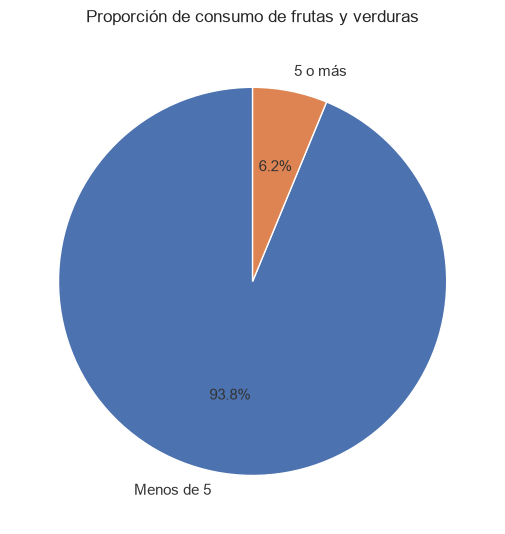

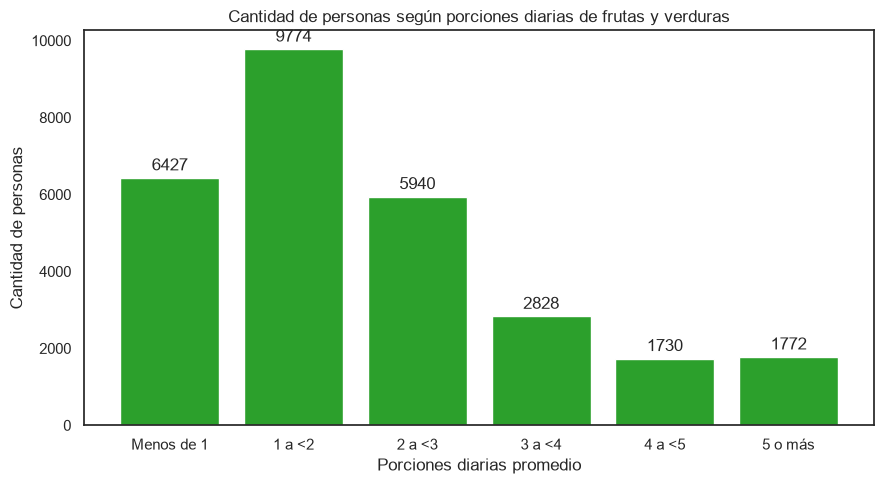

In [14]:
# Hipótesis 4: Proporción (Fig. 11) y distribución por intervalos (Fig. 12)
sns.set_theme(style="white")

# 1. Gráfico de torta: cumplimiento de 5 porciones (Fig. 11)
fv_min = 5
fv = df["promedio_fv_diario"].dropna()
frutas_count = [
    (fv < fv_min).sum(),
    (fv >= fv_min).sum(),
]
labels = ["Menos de 5", "5 o más"]

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(
    frutas_count,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#4C72B0', '#DD8452'],
    wedgeprops={'edgecolor': 'white', 'linewidth': 1},
    textprops={'fontsize': 10.5, 'color': '#333333'},
)
ax.set_title("Proporción de consumo de frutas y verduras", fontsize=12, pad=12)
plt.tight_layout()
plt.show()

# 2. Gráfico de barras verde: cantidad de personas por intervalos (Fig. 12)
porciones = df['promedio_fv_diario'].dropna()
porciones_bins = pd.cut(
    porciones,
    bins=[-np.inf, 1, 2, 3, 4, 5, np.inf],
    labels=['Menos de 1', '1 a <2', '2 a <3', '3 a <4', '4 a <5', '5 o más'],
    right=False,
)
conteo_porciones = porciones_bins.value_counts(sort=False)

fig, ax = plt.subplots(figsize=(9, 5))
barras_porciones = ax.bar(
    conteo_porciones.index.astype(str),
    conteo_porciones.values,
    color='#2ca02c',
)
ax.bar_label(barras_porciones, padding=3)
ax.set_title('Cantidad de personas según porciones diarias de frutas y verduras')
ax.set_xlabel('Porciones diarias promedio')
ax.set_ylabel('Cantidad de personas')
plt.tight_layout()
plt.show()

### 4.5. Hipótesis 5: IMC y actividad física (bivariada)

Casos válidos (N): 26771
                        count  mean  std  median
nivel_actividad_fisica                          
1.00                     4595 26.31 4.78   25.54
2.00                     9663 26.92 4.99   26.18
3.00                    12513 27.95 5.60   27.18
                            OLS Regression Results                            
Dep. Variable:                    imc   R-squared:                       0.015
Model:                            OLS   Adj. R-squared:                  0.015
Method:                 Least Squares   F-statistic:                     203.4
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           2.15e-88
Time:                        23:46:57   Log-Likelihood:                -82375.
No. Observations:               26771   AIC:                         1.648e+05
Df Residuals:                   26768   BIC:                         1.648e+05
Df Model:                           2                                         
Covariance Type:   

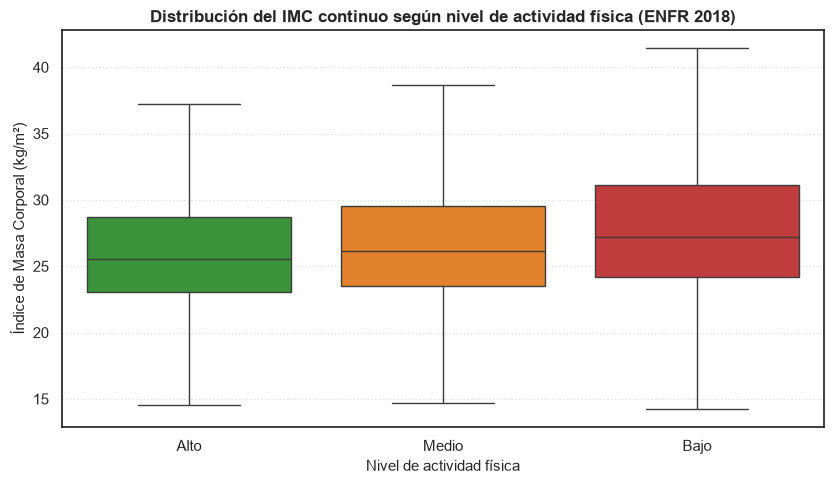

In [15]:
### Hipotesis 5: imc y actividad_fisica
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
import seaborn as sns
import statsmodels.formula.api as smf

# 1. Filtrar casos válidos usando la variable CONTINUA 'imc'
df_h5 = df[['imc', 'nivel_actividad_fisica']].dropna().copy()

# Asegurar etiquetas legibles (ajustar códigos según tu dataset: ej. 1=Alto, 2=Medio, 3=Bajo)
# df_h5['actividad_label'] = df_h5['nivel_actividad_fisica'].map({1: 'Alto', 2: 'Medio', 3: 'Bajo'})

print(f'Casos válidos (N): {len(df_h5)}')
print(df_h5.groupby('nivel_actividad_fisica')['imc'].agg(['count', 'mean', 'std', 'median']))

# 2. Modelo de Regresión Lineal (OLS) con categoría de referencia (ej. Alto o Bajo)
# Esto evalúa si el IMC medio cambia según el nivel de actividad física (equivale a ANOVA)
modelo_h5 = smf.ols('imc ~ C(nivel_actividad_fisica)', data=df_h5).fit()
print(modelo_h5.summary())

# Contraste no paramétrico complementario (Kruskal-Wallis)
grupos = [grupo['imc'].values for _, grupo in df_h5.groupby('nivel_actividad_fisica')]
stat_kw, p_kw = stats.kruskal(*grupos)
print(f'\nKruskal-Wallis: H = {stat_kw:.4f}, p-valor = {p_kw:.4e}')

# 3. Gráfico Boxplot (reemplaza a los gráficos de torta)
mapa_af = {1.0: 'Alto', 2.0: 'Medio', 3.0: 'Bajo'}
df_h5['af_etiqueta'] = df_h5['nivel_actividad_fisica'].map(mapa_af)

plt.figure(figsize=(8.5, 5))
sns.boxplot(
    data=df_h5,
    x='af_etiqueta',
    y='imc',
    hue='af_etiqueta',
    order=['Alto', 'Medio', 'Bajo'],
    palette=['#2CA02C', '#FF7F0E', '#D62728'],
    legend=False,
    showfliers=False
)
plt.xlabel('Nivel de actividad física', fontsize=11)
plt.ylabel('Índice de Masa Corporal (kg/m²)', fontsize=11)
plt.title('Distribución del IMC continuo según nivel de actividad física (ENFR 2018)', fontsize=12, fontweight='bold')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### 4.6. Hipótesis 6: relación entre variables de salud (PCA)


 H6: PCA de las cinco variables de salud
Registros originales: 29224
Registros utilizados: 5039
Registros excluidos: 24185

VARIANZA EXPLICADA:
  Componente  Varianza explicada  Varianza acumulada
0        PC1                0.47                0.47
1        PC2                0.20                0.67

CARGAS DE LAS VARIABLES:
                         PC1   PC2
Indice de Masa Corporal 0.53 -0.49
Presion Sistolica       0.43  0.46
Perimetro de Cintura    0.56 -0.39
Edad                    0.39  0.61
Glucemia                0.25  0.17


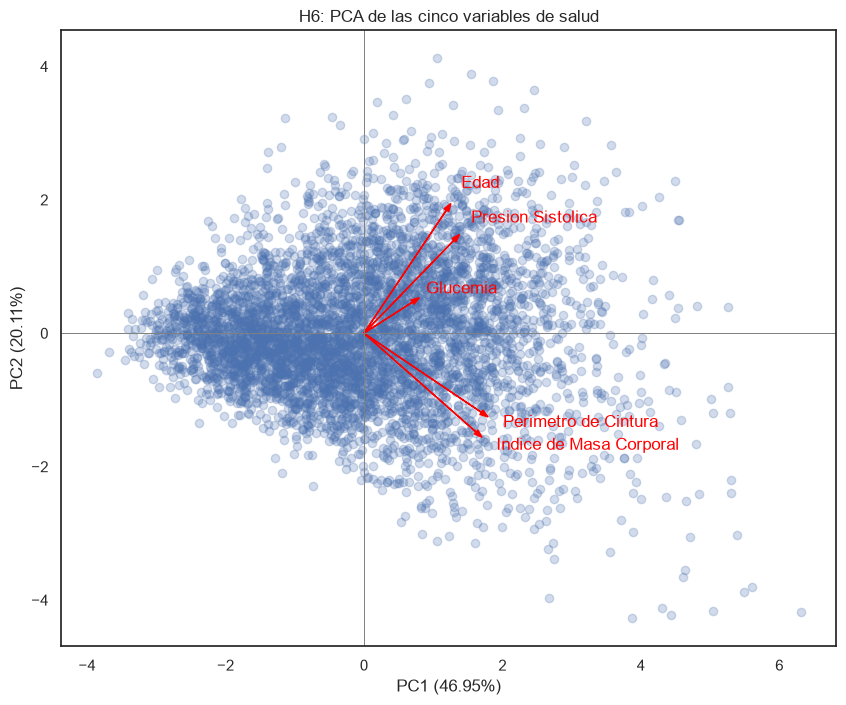

In [16]:
# HIPÓTESIS 6: RELACIÓN ENTRE VARIABLES DE SALUD

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


# Función para realizar y graficar el PCA
def realizar_pca(columnas, nombres, titulo):

    # Selección de variables y eliminación de registros incompletos
    Hipo = df[columnas].dropna().copy()

    print("\n", titulo)
    print("Registros originales:", len(df))
    print("Registros utilizados:", len(Hipo))
    print("Registros excluidos:", len(df) - len(Hipo))

    # Estandarización
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(Hipo)

    # PCA
    pca = PCA(n_components=2)
    componentes = pca.fit_transform(X_scaled)

    # Varianza explicada
    varianza = pd.DataFrame({
        'Componente': ['PC1', 'PC2'],
        'Varianza explicada': pca.explained_variance_ratio_,
        'Varianza acumulada': np.cumsum(pca.explained_variance_ratio_)
    })

    print("\nVARIANZA EXPLICADA:")
    print(varianza)

    # Cargas de las variables
    loadings = pd.DataFrame(
        pca.components_.T,
        index=nombres,
        columns=['PC1', 'PC2']
    )

    print("\nCARGAS DE LAS VARIABLES:")
    print(loadings)

    # Gráfico de componentes y proyección de variables
    fig, ax = plt.subplots(figsize=(10, 8))

    ax.scatter(
        componentes[:, 0],
        componentes[:, 1],
        alpha=0.25
    )

    # Escala de las flechas para visualizar las cargas
    escala = (
        min(
            np.max(np.abs(componentes[:, 0])),
            np.max(np.abs(componentes[:, 1]))
        ) * 0.75
    )

    for i, nombre in enumerate(nombres):
        x = loadings.iloc[i, 0] * escala
        y = loadings.iloc[i, 1] * escala

        ax.arrow(
            0, 0, x, y,
            color='red',
            head_width=escala * 0.025,
            length_includes_head=True
        )

        ax.text(x * 1.12, y * 1.12, nombre, color='red')

    ax.axhline(0, color='gray', linewidth=0.7)
    ax.axvline(0, color='gray', linewidth=0.7)

    ax.set_xlabel(
        f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)"
    )
    ax.set_ylabel(
        f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)"
    )

    ax.set_title(titulo)
    plt.show()

    return pca, loadings, varianza, Hipo


# Variables seleccionadas
columnas = [
    'imc_bima',
    'promedio_sistolica',
    'bima13',
    'bhch04',
    'bimq05'
]

nombres = [
    'Indice de Masa Corporal',
    'Presion Sistolica',
    'Perimetro de Cintura',
    'Edad',
    'Glucemia'
]

pca_h6, cargas_h6, varianza_h6, Hipo = realizar_pca(
    columnas,
    nombres,
    'H6: PCA de las cinco variables de salud'
)

#### 4.6.1. Análisis complementario: IMC, cintura y glucemia


 H6: PCA complementario - IMC, cintura y glucemia
Registros originales: 29224
Registros utilizados: 5114
Registros excluidos: 24110

VARIANZA EXPLICADA:
  Componente  Varianza explicada  Varianza acumulada
0        PC1                0.63                0.63
1        PC2                0.31                0.93

CARGAS DE LAS VARIABLES:
                         PC1   PC2
Indice de Masa Corporal 0.67 -0.23
Perimetro de Cintura    0.68 -0.19
Glucemia                0.30  0.96


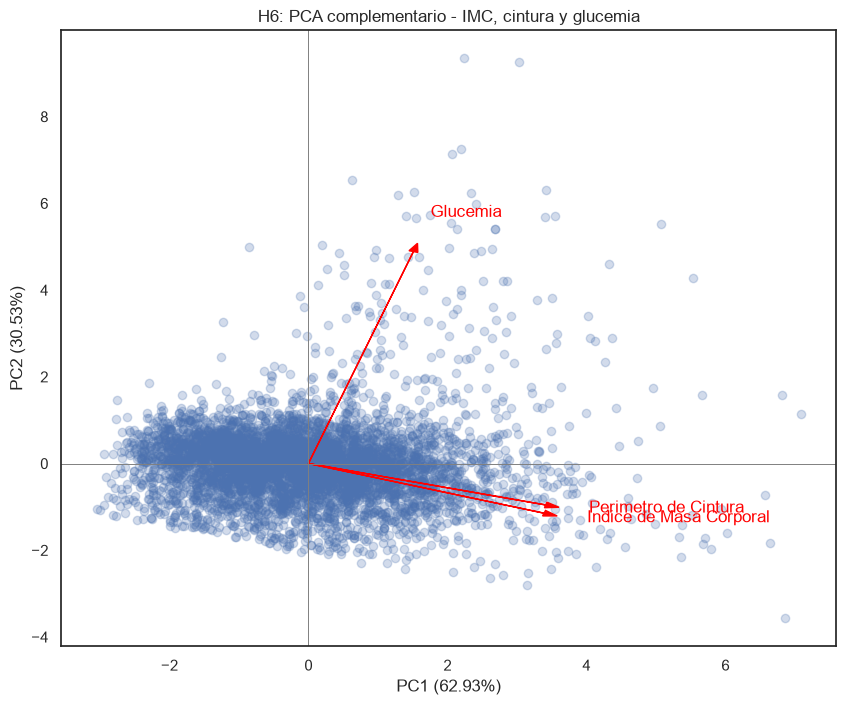

In [17]:
# HIPÓTESIS 6: ANÁLISIS COMPLEMENTARIO
# IMC, cintura y glucemia

columnas = [
    'imc_bima',
    'bima13',
    'bimq05'
]

nombres = [
    'Indice de Masa Corporal',
    'Perimetro de Cintura',
    'Glucemia'
]

pca_h6_2, cargas_h6_2, varianza_h6_2, Hipo2 = realizar_pca(
    columnas,
    nombres,
    'H6: PCA complementario - IMC, cintura y glucemia'
)

#### 4.6.2. Análisis complementario: presión, edad y glucemia


 H6: PCA complementario - Presion, edad y glucemia
Registros originales: 29224
Registros utilizados: 5107
Registros excluidos: 24117

VARIANZA EXPLICADA:
  Componente  Varianza explicada  Varianza acumulada
0        PC1                0.51                0.51
1        PC2                0.30                0.82

CARGAS DE LAS VARIABLES:
                   PC1   PC2
Presion Sistolica 0.65 -0.28
Edad              0.66 -0.25
Glucemia          0.38  0.93


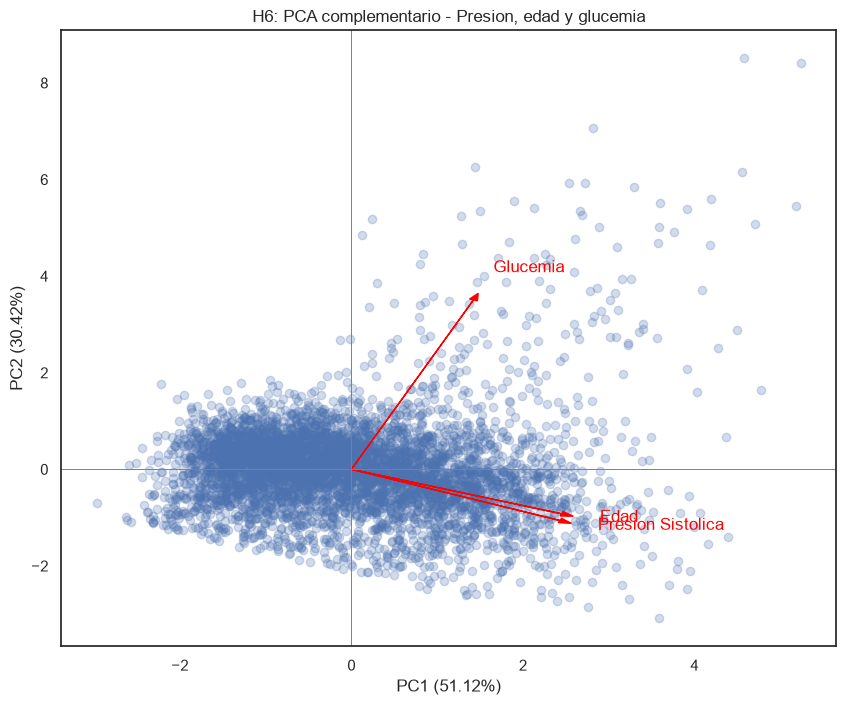

In [18]:
# HIPÓTESIS 6: ANÁLISIS COMPLEMENTARIO
# Presión, edad y glucemia

columnas = [
    'promedio_sistolica',
    'bhch04',
    'bimq05'
]

nombres = [
    'Presion Sistolica',
    'Edad',
    'Glucemia'
]

pca_h6_3, cargas_h6_3, varianza_h6_3, Hipo3 = realizar_pca(
    columnas,
    nombres,
    'H6: PCA complementario - Presion, edad y glucemia'
)

#### 4.6.3. Matriz de correlación de pearson y spearman 

Cantidad de observaciones: 5039

--- MATRIZ DE CORRELACIÓN DE PEARSON (r) ---
                         Índice de Masa Corporal  Presión Sistólica  \
Índice de Masa Corporal                     1.00               0.32   
Presión Sistólica                           0.32               1.00   
Perímetro de Cintura                        0.80               0.35   
Edad                                        0.22               0.45   
Glucemia                                    0.18               0.15   

                         Perímetro de Cintura  Edad  Glucemia  
Índice de Masa Corporal                  0.80  0.22      0.18  
Presión Sistólica                        0.35  0.45      0.15  
Perímetro de Cintura                     1.00  0.31      0.20  
Edad                                     0.31  1.00      0.16  
Glucemia                                 0.20  0.16      1.00  

--- MATRIZ DE CORRELACIÓN DE SPEARMAN (rho) ---
                         Índice de Masa Corporal  Presión Sist

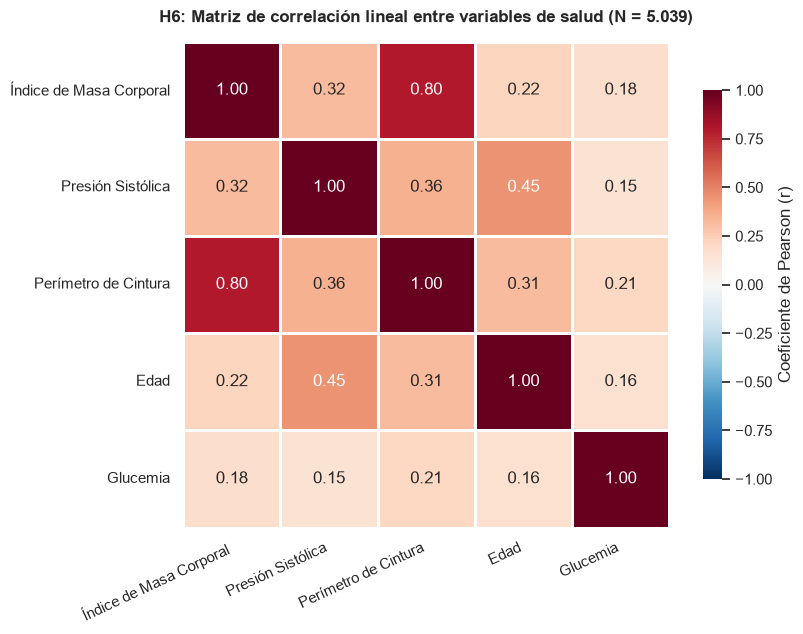

In [19]:
## Matriz de correlacion de pearson y spearman
import seaborn as sns
from scipy.stats import pearsonr
import pandas as pd
import matplotlib.pyplot as plt

# 1. Reconstruir la muestra del PCA principal (N = 5.039)
columnas_h6 = [
    'imc_bima',
    'promedio_sistolica',
    'bima13',
    'bhch04',
    'bimq05'
]

nombres = [
    'Índice de Masa Corporal',
    'Presión Sistólica',
    'Perímetro de Cintura',
    'Edad',
    'Glucemia'
]

Hipo_etiquetas = df[columnas_h6].dropna().copy()
Hipo_etiquetas.columns = nombres

print("Cantidad de observaciones:", len(Hipo_etiquetas))

# 2. Matrices de correlación
corr_pearson = Hipo_etiquetas.corr(method='pearson')
corr_spearman = Hipo_etiquetas.corr(method='spearman')

print("\n--- MATRIZ DE CORRELACIÓN DE PEARSON (r) ---")
print(corr_pearson.round(3))

print("\n--- MATRIZ DE CORRELACIÓN DE SPEARMAN (rho) ---")
print(corr_spearman.round(3))

# 3. P-valores de Pearson
p_valores = pd.DataFrame(
    index=nombres,
    columns=nombres,
    dtype=float
)

for col1 in nombres:
    for col2 in nombres:
        if col1 == col2:
            p_valores.loc[col1, col2] = 0
        else:
            _, p_val = pearsonr(
                Hipo_etiquetas[col1],
                Hipo_etiquetas[col2]
            )
            p_valores.loc[col1, col2] = p_val

print("\n--- P-VALORES DE CORRELACIÓN DE PEARSON ---")
print(p_valores.round(4))

# 4. Heatmap de Pearson
plt.figure(figsize=(8.5, 6.5))

sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.8,
    cbar_kws={
        "shrink": 0.8,
        "label": "Coeficiente de Pearson (r)"
    }
)

plt.title(
    "H6: Matriz de correlación lineal entre variables de salud (N = 5.039)",
    fontsize=12,
    fontweight="bold",
    pad=14
)

plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()